In [1]:

from google.colab import files

uploaded = files.upload()


Saving Sample - Superstore.xls to Sample - Superstore.xls


In [2]:

file_name = next(iter(uploaded))

print("Uploaded file:", file_name)
print("File size:", round(len(uploaded[file_name]) / 1024, 2), "KB")


Uploaded file: Sample - Superstore.xls
File size: 3299.0 KB


In [3]:

import pandas as pd
import io

file_name = next(iter(uploaded))
excel_file = pd.ExcelFile(io.BytesIO(uploaded[file_name]))

print("Worksheets found:", excel_file.sheet_names)


Worksheets found: ['Orders', 'People', 'Returns']


In [4]:

orders = pd.read_excel(excel_file, sheet_name="Orders")
returns = pd.read_excel(excel_file, sheet_name="Returns")
people = pd.read_excel(excel_file, sheet_name="People")

print("Orders dataset:", orders.shape)
print("Returns dataset:", returns.shape)
print("People dataset:", people.shape)


Orders dataset: (9994, 21)
Returns dataset: (800, 2)
People dataset: (4, 2)


In [5]:

# Display every column name
print("COLUMN NAMES")
print(orders.columns.tolist())

# Inspect data types and non-null counts
print("\nDATASET INFORMATION")
orders.info()


COLUMN NAMES
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   int64         
 1   Order ID        9994 non-null   object        
 2   Order Date      9994 non-null   datetime64[ns]
 3   Ship Date       9994 non-null   datetime64[ns]
 4   Ship Mode       9994 non-null   object        
 5   Customer ID     9994 non-null   object        
 6   Customer Name   9994 non-null   object        
 7   Segment         9994 non-null   object        
 8   Country/Region  9994 non-null   object        
 9   City           

In [6]:

# Count missing values in each column
missing_values = orders.isnull().sum()

print("MISSING VALUES BY COLUMN")
display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame(name="Missing Count")
)

# Count exact duplicate rows
print("Exact duplicate rows:", orders.duplicated().sum())


MISSING VALUES BY COLUMN


,Missing Count
Postal Code,11


Exact duplicate rows: 0


In [7]:

print("Total sales:", round(orders["Sales"].sum(), 2))
print("Total profit:", round(orders["Profit"].sum(), 2))
print("Unique orders:", orders["Order ID"].nunique())
print("Unique customers:", orders["Customer ID"].nunique())

print(
    "Order date range:",
    orders["Order Date"].min(),
    "to",
    orders["Order Date"].max()
)


Total sales: 2297200.86
Total profit: 286397.02
Unique orders: 5009
Unique customers: 793
Order date range: 2018-01-03 00:00:00 to 2021-12-30 00:00:00


In [8]:

# Inspect numerical columns
print("NUMERICAL SUMMARY")
display(orders[["Sales", "Quantity", "Discount", "Profit"]].describe())

# Check unusual values
print("\nUNUSUAL VALUE CHECKS")
print("Sales <= 0:", (orders["Sales"] <= 0).sum())
print("Quantity <= 0:", (orders["Quantity"] <= 0).sum())
print("Discount < 0:", (orders["Discount"] < 0).sum())
print("Discount > 1:", (orders["Discount"] > 1).sum())
print("Negative-profit transactions:", (orders["Profit"] < 0).sum())
print("Zero-profit transactions:", (orders["Profit"] == 0).sum())


NUMERICAL SUMMARY


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000



UNUSUAL VALUE CHECKS
Sales <= 0: 0
Quantity <= 0: 0
Discount < 0: 0
Discount > 1: 0
Negative-profit transactions: 1871
Zero-profit transactions: 65


In [9]:

print("RETURNS WORKSHEET")
display(returns.head(10))

print("\nReturn status counts:")
print(returns["Returned"].value_counts(dropna=False))

print("\nUnique returned order IDs:", returns["Order ID"].nunique())

print(
    "\nReturned order IDs not found in Orders:",
    (~returns["Order ID"].isin(orders["Order ID"])).sum()
)


RETURNS WORKSHEET


,Returned,Order ID
0,Yes,CA-2018-100762
1,Yes,CA-2018-100762
2,Yes,CA-2018-100762
3,Yes,CA-2018-100762
4,Yes,CA-2018-100867
5,Yes,CA-2018-102652
6,Yes,CA-2018-102652
7,Yes,CA-2018-102652
8,Yes,CA-2018-102652
9,Yes,CA-2018-103373



Return status counts:
Returned
Yes    800
Name: count, dtype: int64

Unique returned order IDs: 296

Returned order IDs not found in Orders: 0


In [10]:

print("Rows with missing postal codes:")
display(orders.loc[orders["Postal Code"].isna()].head(15))


Rows with missing postal codes:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
2234,2235,CA-2021-104066,2021-12-05,2021-12-10,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,...,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03,7,0.0,67.6599
5274,5275,CA-2019-162887,2019-11-07,2019-11-09,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,...,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20,3,0.0,178.8000
8798,8799,US-2020-150140,2020-04-06,2020-04-10,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,...,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75,5,0.0,336.6350
9146,9147,US-2020-165505,2020-01-23,2020-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98,2,0.0,42.9914
9147,9148,US-2020-165505,2020-01-23,2020-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04,6,0.0,2.7336
9148,9149,US-2020-165505,2020-01-23,2020-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,...,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29,13,0.0,406.7154
9386,9387,US-2021-127292,2021-01-19,2021-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92,4,0.0,37.5624
9387,9388,US-2021-127292,2021-01-19,2021-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28,1,0.0,5.7716
9388,9389,US-2021-127292,2021-01-19,2021-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94,3,0.0,152.0232
9389,9390,US-2021-127292,2021-01-19,2021-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,...,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04,1,0.0,0.9588


In [12]:

# Preserve the original Orders data
orders_clean = orders.copy()

# Create a unique list of returned order IDs
returned_order_ids = returns["Order ID"].drop_duplicates()

# Flag each order line as returned or not returned
orders_clean["Is Returned"] = (
    orders_clean["Order ID"].isin(returned_order_ids)
)

# Validate the new flag
print("Original rows:", len(orders))
print("Working-copy rows:", len(orders_clean))
print("Returned order IDs:", len(returned_order_ids))
print(
    "Distinct returned orders matched:",
    orders_clean.loc[
        orders_clean["Is Returned"], "Order ID"
    ].nunique()
)


Original rows: 9994
Working-copy rows: 9994
Returned order IDs: 296
Distinct returned orders matched: 296


In [13]:

# Aggregate sales and profit by product category
category_profit = (
    orders_clean
    .groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Order_Count=("Order ID", "nunique")
    )
    .reset_index()
)

# Calculate profit margin from aggregated totals
category_profit["Profit_Margin_%"] = (
    category_profit["Total_Profit"]
    / category_profit["Total_Sales"] * 100
)

# Sort categories by total profit
category_profit = category_profit.sort_values(
    "Total_Profit", ascending=False
)

display(
    category_profit.round({
        "Total_Sales": 2,
        "Total_Profit": 2,
        "Profit_Margin_%": 2
    })
)


,Category,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
2,Technology,836154.03,145454.95,6939,1544,17.40
1,Office Supplies,719047.03,122490.80,22906,3742,17.04
0,Furniture,741999.80,18451.27,8028,1764,2.49


In [14]:

subcategory_profit = (
    orders_clean
    .groupby(["Category", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

subcategory_profit["Profit_Margin_%"] = (
    subcategory_profit["Total_Profit"]
    / subcategory_profit["Total_Sales"] * 100
)

print("TOP 5 SUB-CATEGORIES BY PROFIT")
display(
    subcategory_profit
    .sort_values("Total_Profit", ascending=False)
    .head(5)
    .round(2)
)

print("BOTTOM 5 SUB-CATEGORIES BY PROFIT")
display(
    subcategory_profit
    .sort_values("Total_Profit", ascending=True)
    .head(5)
    .round(2)
)


TOP 5 SUB-CATEGORIES BY PROFIT


,Category,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
14,Technology,Copiers,149528.03,55617.82,234,37.20
16,Technology,Phones,330007.05,44515.73,3289,13.49
13,Technology,Accessories,167380.32,41936.64,2976,25.05
10,Office Supplies,Paper,78479.21,34053.57,5178,43.39
6,Office Supplies,Binders,203412.73,30221.76,5974,14.86


BOTTOM 5 SUB-CATEGORIES BY PROFIT


,Category,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
3,Furniture,Tables,206965.53,-17725.48,1241,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,868,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,647,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,914,31.40
15,Technology,Machines,189238.63,3384.76,440,1.79


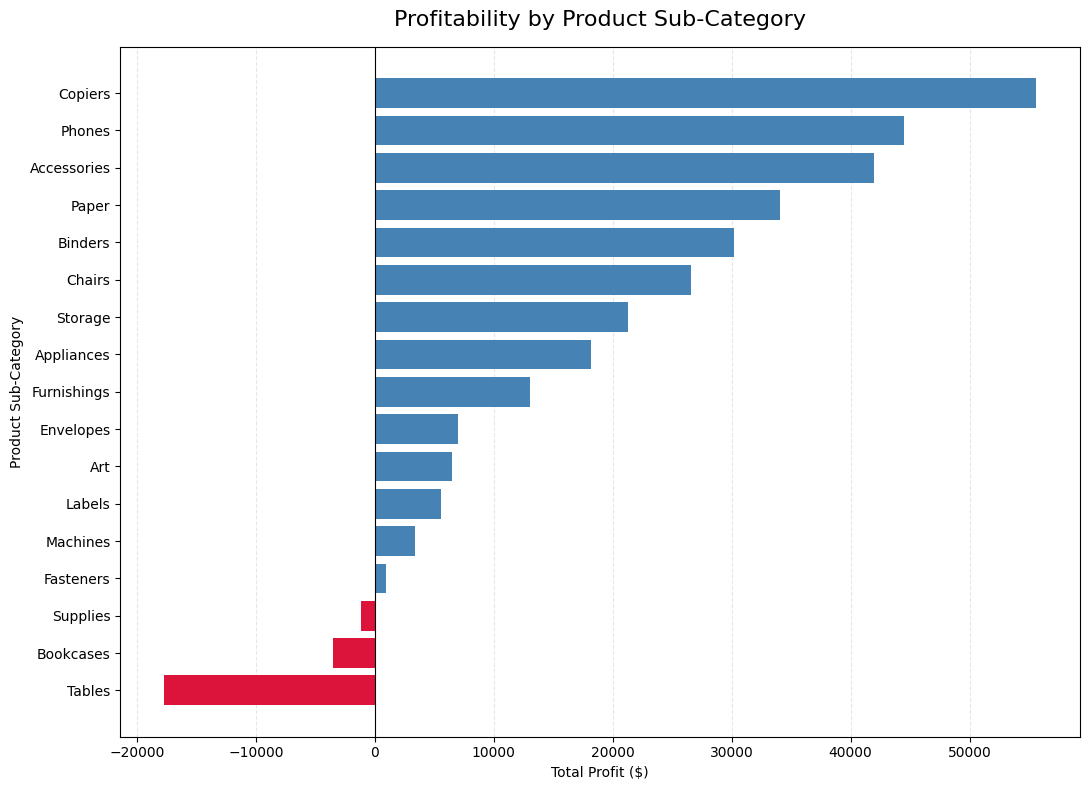

In [15]:

import matplotlib.pyplot as plt

# Sort sub-categories by profit
plot_data = subcategory_profit.sort_values("Total_Profit")

# Highlight losses separately from profitable sub-categories
bar_colors = [
    "crimson" if profit < 0 else "steelblue"
    for profit in plot_data["Total_Profit"]
]

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    plot_data["Sub-Category"],
    plot_data["Total_Profit"],
    color=bar_colors
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Profitability by Product Sub-Category",
    fontsize=16,
    pad=15
)
ax.set_xlabel("Total Profit ($)")
ax.set_ylabel("Product Sub-Category")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [16]:

# Summarise performance at each discount level
discount_analysis = (
    orders_clean
    .groupby("Discount")
    .agg(
        Transaction_Rows=("Order ID", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Loss_Making_Rows=("Profit", lambda x: (x < 0).sum())
    )
    .reset_index()
)

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"] * 100
)

# Convert discount fractions to percentages for readability
discount_analysis["Discount_%"] = (
    discount_analysis["Discount"] * 100
)

discount_analysis = discount_analysis.sort_values("Discount")

display(
    discount_analysis[
        [
            "Discount_%",
            "Transaction_Rows",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%",
            "Loss_Making_Rows"
        ]
    ].round(2)
)


,Discount_%,Transaction_Rows,Total_Sales,Total_Profit,Profit_Margin_%,Loss_Making_Rows
0,0.0,4798,1087908.47,320987.60,29.51,0
1,10.0,94,54369.35,9029.18,16.61,4
2,15.0,52,27558.52,1418.99,5.15,17
3,20.0,3657,764594.37,90337.31,11.82,502
4,30.0,227,103226.66,-10369.28,-10.05,208
5,32.0,27,14493.46,-2391.14,-16.50,27
6,40.0,206,116417.78,-23057.05,-19.81,180
7,45.0,11,5484.97,-2493.11,-45.45,11
8,50.0,66,58918.54,-20506.43,-34.80,66
9,60.0,138,6644.70,-5944.66,-89.46,138


In [18]:

target_products = orders_clean[
    orders_clean["Sub-Category"].isin(["Tables", "Bookcases"])
]

target_discount_analysis = (
    target_products
    .groupby(["Sub-Category", "Discount"])
    .agg(
        Transaction_Rows=("Order ID", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Loss_Making_Rows=("Profit", lambda x: (x < 0).sum())
    )
    .reset_index()
)

target_discount_analysis["Profit_Margin_%"] = (
    target_discount_analysis["Total_Profit"]
    / target_discount_analysis["Total_Sales"] * 100
)

target_discount_analysis["Discount_%"] = (
    target_discount_analysis["Discount"] * 100
)

display(
    target_discount_analysis[
        [
            "Sub-Category",
            "Discount_%",
            "Transaction_Rows",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%",
            "Loss_Making_Rows"
        ]
    ]
    .sort_values(["Sub-Category", "Discount_%"])
    .round(2)
)


,Sub-Category,Discount_%,Transaction_Rows,Total_Sales,Total_Profit,Profit_Margin_%,Loss_Making_Rows
0,Bookcases,0.0,60,31935.98,6075.71,19.02,0
1,Bookcases,15.0,52,27558.52,1418.99,5.15,17
2,Bookcases,20.0,46,26841.50,130.50,0.49,23
3,Bookcases,30.0,10,4282.70,-555.87,-12.98,9
4,Bookcases,32.0,27,14493.46,-2391.14,-16.50,27
5,Bookcases,50.0,18,7308.46,-4255.81,-58.23,18
6,Bookcases,70.0,15,2459.38,-3894.94,-158.37,15
7,Tables,0.0,72,71578.76,13276.30,18.55,0
8,Tables,20.0,71,45430.23,-303.56,-0.67,31
9,Tables,30.0,54,25182.15,-3402.33,-13.51,50


In [19]:

customer_analysis = (
    orders_clean
    .groupby(["Customer ID", "Customer Name"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Units_Purchased=("Quantity", "sum")
    )
    .reset_index()
)

customer_analysis["Profit_Margin_%"] = (
    customer_analysis["Total_Profit"]
    / customer_analysis["Total_Sales"] * 100
)

customer_analysis["Customer_Type"] = (
    customer_analysis["Unique_Orders"]
    .apply(lambda x: "Repeat" if x > 1 else "One-time")
)

print("Customer summary:")
display(customer_analysis.head())

print("\nTop 10 customers by total sales:")
display(
    customer_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
    .round(2)
)


Customer summary:


,Customer ID,Customer Name,Total_Sales,Total_Profit,Unique_Orders,Units_Purchased,Profit_Margin_%,Customer_Type
0,AA-10315,Alex Avila,5563.560,-362.8825,5,30,-6.522487,Repeat
1,AA-10375,Allen Armold,1056.390,277.3824,9,41,26.257575,Repeat
2,AA-10480,Andrew Allen,1790.512,435.8274,4,36,24.340937,Repeat
3,AA-10645,Anna Andreadi,5086.935,857.8033,6,64,16.862871,Repeat
4,AB-10015,Aaron Bergman,886.156,129.3465,3,13,14.596358,Repeat



Top 10 customers by total sales:


,Customer ID,Customer Name,Total_Sales,Total_Profit,Unique_Orders,Units_Purchased,Profit_Margin_%,Customer_Type
700,SM-20320,Sean Miller,25043.05,-1980.74,5,50,-7.91,Repeat
741,TC-20980,Tamara Chand,19052.22,8981.32,5,42,47.14,Repeat
621,RB-19360,Raymond Buch,15117.34,6976.10,6,71,46.15,Repeat
730,TA-21385,Tom Ashbrook,14595.62,4703.79,4,36,32.23,Repeat
6,AB-10105,Adrian Barton,14473.57,5444.81,10,73,37.62,Repeat
434,KL-16645,Ken Lonsdale,14175.23,806.85,12,113,5.69,Repeat
669,SC-20095,Sanjit Chand,14142.33,5757.41,9,87,40.71,Repeat
327,HL-15040,Hunter Lopez,12873.30,5622.43,6,50,43.68,Repeat
683,SE-20110,Sanjit Engle,12209.44,2650.68,11,78,21.71,Repeat
131,CC-12370,Christopher Conant,12129.07,2177.05,5,34,17.95,Repeat


In [20]:

customer_type_summary = (
    customer_analysis
    .groupby("Customer_Type")
    .agg(
        Customers=("Customer ID", "nunique"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Average_Customer_Sales=("Total_Sales", "mean"),
        Average_Orders=("Unique_Orders", "mean")
    )
    .reset_index()
)

customer_type_summary["Sales_Share_%"] = (
    customer_type_summary["Total_Sales"]
    / customer_type_summary["Total_Sales"].sum() * 100
)

customer_type_summary["Profit_Margin_%"] = (
    customer_type_summary["Total_Profit"]
    / customer_type_summary["Total_Sales"] * 100
)

display(customer_type_summary.round(2))


,Customer_Type,Customers,Total_Sales,Total_Profit,Average_Customer_Sales,Average_Orders,Sales_Share_%,Profit_Margin_%
0,One-time,12,5167.64,767.37,430.64,1.0,0.22,14.85
1,Repeat,781,2292033.22,285629.65,2934.74,6.4,99.78,12.46


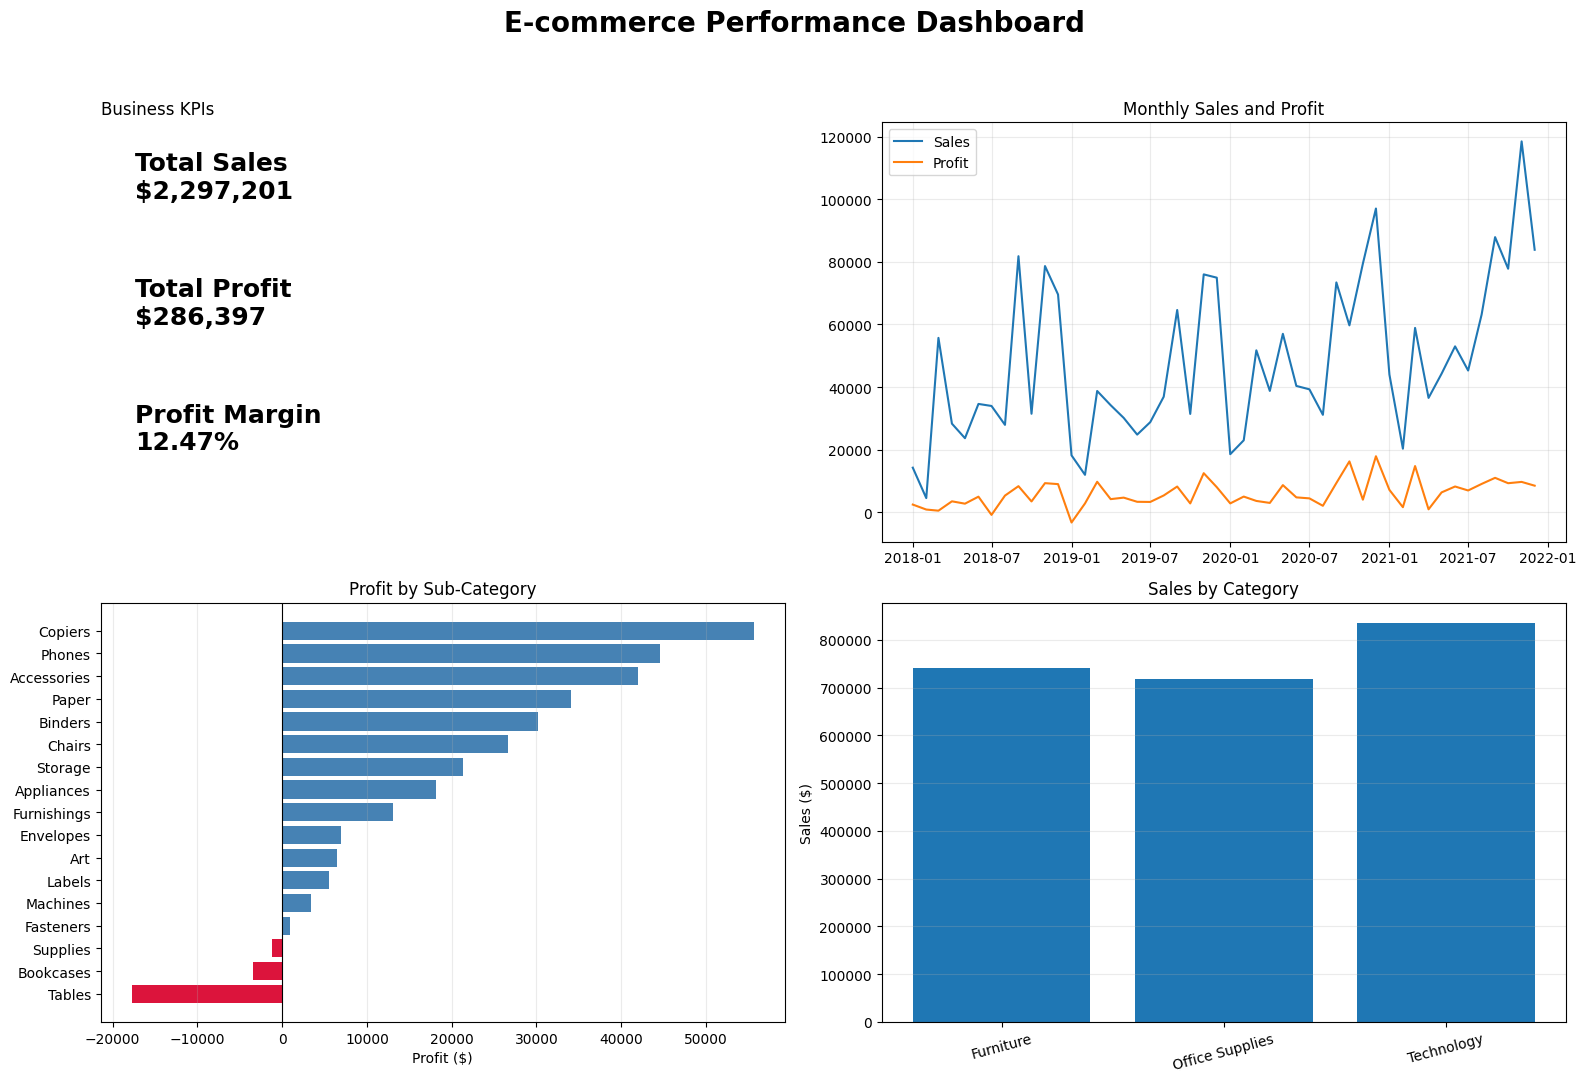

In [21]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Prepare monthly trends
monthly = (
    orders_clean
    .set_index("Order Date")
    .resample("MS")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

# Prepare category-level figures
category_dashboard = (
    orders_clean
    .groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

# Overall KPIs
total_sales = orders_clean["Sales"].sum()
total_profit = orders_clean["Profit"].sum()
overall_margin = total_profit / total_sales

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    "E-commerce Performance Dashboard",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# KPI summary
axes[0, 0].axis("off")
axes[0, 0].text(
    0.05, 0.82,
    f"Total Sales\n${total_sales:,.0f}",
    fontsize=18, fontweight="bold"
)
axes[0, 0].text(
    0.05, 0.52,
    f"Total Profit\n${total_profit:,.0f}",
    fontsize=18, fontweight="bold"
)
axes[0, 0].text(
    0.05, 0.22,
    f"Profit Margin\n{overall_margin:.2%}",
    fontsize=18, fontweight="bold"
)
axes[0, 0].set_title("Business KPIs", loc="left")

# Monthly sales and profit
axes[0, 1].plot(
    monthly["Order Date"],
    monthly["Sales"],
    label="Sales"
)
axes[0, 1].plot(
    monthly["Order Date"],
    monthly["Profit"],
    label="Profit"
)
axes[0, 1].set_title("Monthly Sales and Profit")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

# Profit by sub-category
plot_data = subcategory_profit.sort_values("Total_Profit")
bar_colors = [
    "crimson" if value < 0 else "steelblue"
    for value in plot_data["Total_Profit"]
]
axes[1, 0].barh(
    plot_data["Sub-Category"],
    plot_data["Total_Profit"],
    color=bar_colors
)
axes[1, 0].axvline(0, color="black", linewidth=0.8)
axes[1, 0].set_title("Profit by Sub-Category")
axes[1, 0].set_xlabel("Profit ($)")
axes[1, 0].grid(axis="x", alpha=0.25)

# Category sales
axes[1, 1].bar(
    category_dashboard["Category"],
    category_dashboard["Sales"]
)
axes[1, 1].set_title("Sales by Category")
axes[1, 1].set_ylabel("Sales ($)")
axes[1, 1].tick_params(axis="x", rotation=15)
axes[1, 1].grid(axis="y", alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


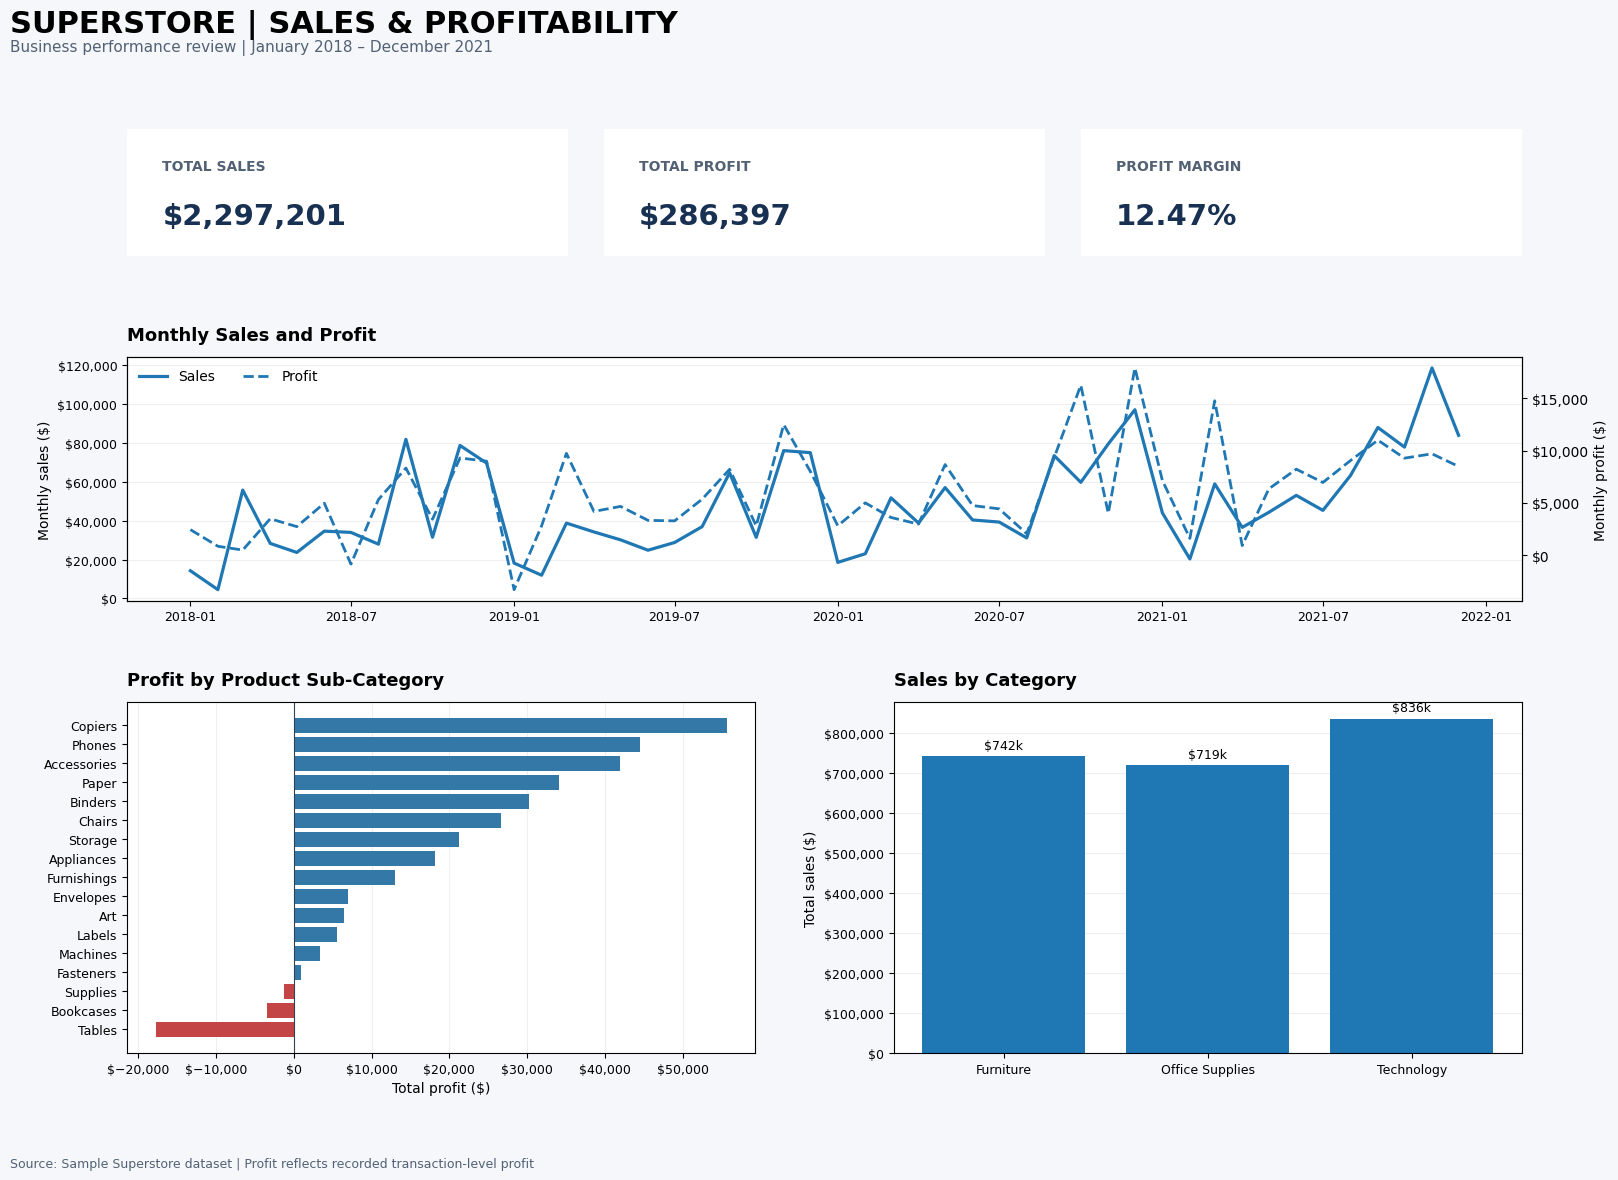

In [22]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

# ---------- Prepare the data ----------
monthly = (
    orders_clean.set_index("Order Date")
    .resample("MS")
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    .reset_index()
)

category_dashboard = (
    orders_clean.groupby("Category")
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    .reset_index()
)

subcategory_dashboard = (
    orders_clean.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

total_sales = orders_clean["Sales"].sum()
total_profit = orders_clean["Profit"].sum()
profit_margin = total_profit / total_sales

# ---------- Dashboard layout ----------
fig = plt.figure(figsize=(18, 12), facecolor="#F5F7FA")
gs = fig.add_gridspec(
    3, 2,
    height_ratios=[0.65, 1.25, 1.8],
    hspace=0.42, wspace=0.22
)

fig.suptitle(
    "SUPERSTORE | SALES & PROFITABILITY",
    fontsize=22, fontweight="bold", x=0.06,
    ha="left", y=0.98
)

fig.text(
    0.06, 0.945,
    "Business performance review | January 2018 – December 2021",
    fontsize=11, color="#526174"
)

# ---------- KPI cards ----------
kpis = [
    ("TOTAL SALES", f"${total_sales:,.0f}"),
    ("TOTAL PROFIT", f"${total_profit:,.0f}"),
    ("PROFIT MARGIN", f"{profit_margin:.2%}")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i % 2]) if False else None

# Dedicated KPI row spanning the figure
kpi_grid = gs[0, :].subgridspec(1, 3, wspace=0.08)

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(kpi_grid[0, i])
    ax.set_facecolor("white")
    ax.text(
        0.08, 0.68, label,
        transform=ax.transAxes,
        fontsize=10, fontweight="bold", color="#526174"
    )
    ax.text(
        0.08, 0.25, value,
        transform=ax.transAxes,
        fontsize=21, fontweight="bold", color="#183153"
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# ---------- Monthly trend ----------
ax1 = fig.add_subplot(gs[1, :])
ax1.set_facecolor("white")

ax1.plot(
    monthly["Order Date"], monthly["Sales"],
    linewidth=2.3, label="Sales"
)
ax1.set_ylabel("Monthly sales ($)")
ax1.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)
ax1.grid(axis="y", alpha=0.2)

ax1b = ax1.twinx()
ax1b.plot(
    monthly["Order Date"], monthly["Profit"],
    linewidth=2, linestyle="--", label="Profit"
)
ax1b.set_ylabel("Monthly profit ($)")
ax1b.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1b.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left",
           frameon=False, ncol=2)

ax1.set_title(
    "Monthly Sales and Profit",
    loc="left", fontsize=13, fontweight="bold", pad=12
)

# ---------- Profit by sub-category ----------
ax2 = fig.add_subplot(gs[2, 0])
ax2.set_facecolor("white")

colors = [
    "#C44545" if x < 0 else "#3478A8"
    for x in subcategory_dashboard.values
]

ax2.barh(
    subcategory_dashboard.index,
    subcategory_dashboard.values,
    color=colors
)
ax2.axvline(0, color="#344054", linewidth=0.8)
ax2.set_title(
    "Profit by Product Sub-Category",
    loc="left", fontsize=13, fontweight="bold", pad=12
)
ax2.set_xlabel("Total profit ($)")
ax2.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)
ax2.grid(axis="x", alpha=0.2)
ax2.set_axisbelow(True)

# ---------- Sales by category ----------
ax3 = fig.add_subplot(gs[2, 1])
ax3.set_facecolor("white")

bars = ax3.bar(
    category_dashboard["Category"],
    category_dashboard["Sales"]
)

ax3.set_title(
    "Sales by Category",
    loc="left", fontsize=13, fontweight="bold", pad=12
)
ax3.set_ylabel("Total sales ($)")
ax3.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)
ax3.grid(axis="y", alpha=0.2)
ax3.set_axisbelow(True)

ax3.bar_label(
    bars,
    labels=[f"${x/1000:.0f}k"
            for x in category_dashboard["Sales"]],
    padding=3, fontsize=9
)

# ---------- Final formatting ----------
for ax in [ax1, ax2, ax3]:
    ax.tick_params(labelsize=9)

fig.text(
    0.06, 0.015,
    "Source: Sample Superstore dataset | Profit reflects recorded transaction-level profit",
    fontsize=9, color="#526174"
)

plt.savefig(
    "superstore_executive_dashboard.png",
    dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor()
)

plt.show()


In [23]:

# Quantify losses in the two weakest sub-categories

loss_categories = (
    orders_clean[
        orders_clean["Sub-Category"].isin(["Tables", "Bookcases"])
    ]
    .groupby("Sub-Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Transaction_Rows=("Profit", "size"),
        Loss_Making_Rows=("Profit", lambda x: (x < 0).sum())
    )
    .reset_index()
)

loss_categories["Profit_Margin_%"] = (
    loss_categories["Profit"] / loss_categories["Sales"] * 100
)

overall_profit = orders_clean["Profit"].sum()
combined_loss = loss_categories["Profit"].sum()

print("TABLES AND BOOKCASES: PROFITABILITY REVIEW")
display(loss_categories.round(2))

print(f"\nOverall business profit: ${overall_profit:,.2f}")
print(f"Combined profit/loss: ${combined_loss:,.2f}")
print(
    "Combined losses as a percentage of overall profit: "
    f"{abs(combined_loss) / overall_profit * 100:.2f}%"
)


TABLES AND BOOKCASES: PROFITABILITY REVIEW


,Sub-Category,Sales,Profit,Transaction_Rows,Loss_Making_Rows,Profit_Margin_%
0,Bookcases,114880.00,-3472.56,228,109,-3.02
1,Tables,206965.53,-17725.48,319,203,-8.56



Overall business profit: $286,397.02
Combined profit/loss: $-21,198.04
Combined losses as a percentage of overall profit: 7.40%


In [24]:

# Investigate discount and profitability patterns
# specifically for Tables and Bookcases

discount_profitability = (
    orders_clean[
        orders_clean["Sub-Category"].isin(["Tables", "Bookcases"])
    ]
    .groupby(["Sub-Category", "Discount"])
    .agg(
        Transaction_Rows=("Profit", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Loss_Making_Rows=("Profit", lambda x: (x < 0).sum())
    )
    .reset_index()
)

discount_profitability["Profit_Margin_%"] = (
    discount_profitability["Total_Profit"]
    / discount_profitability["Total_Sales"] * 100
)

discount_profitability["Loss_Row_Rate_%"] = (
    discount_profitability["Loss_Making_Rows"]
    / discount_profitability["Transaction_Rows"] * 100
)

display(
    discount_profitability
    .sort_values(["Sub-Category", "Discount"])
    .round(2)
)


,Sub-Category,Discount,Transaction_Rows,Total_Sales,Total_Profit,Loss_Making_Rows,Profit_Margin_%,Loss_Row_Rate_%
0,Bookcases,0.00,60,31935.98,6075.71,0,19.02,0.00
1,Bookcases,0.15,52,27558.52,1418.99,17,5.15,32.69
2,Bookcases,0.20,46,26841.50,130.50,23,0.49,50.00
3,Bookcases,0.30,10,4282.70,-555.87,9,-12.98,90.00
4,Bookcases,0.32,27,14493.46,-2391.14,27,-16.50,100.00
5,Bookcases,0.50,18,7308.46,-4255.81,18,-58.23,100.00
6,Bookcases,0.70,15,2459.38,-3894.94,15,-158.37,100.00
7,Tables,0.00,72,71578.76,13276.30,0,18.55,0.00
8,Tables,0.20,71,45430.23,-303.56,31,-0.67,43.66
9,Tables,0.30,54,25182.15,-3402.33,50,-13.51,92.59


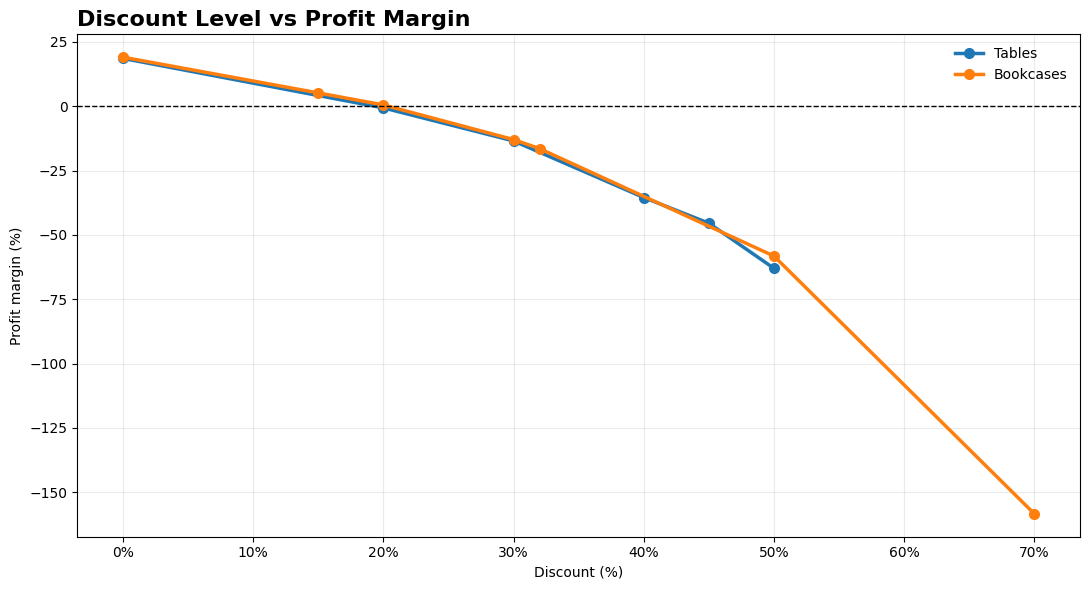

In [25]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

fig, ax = plt.subplots(figsize=(11, 6))

for subcategory in ["Tables", "Bookcases"]:
    data = (
        discount_profitability[
            discount_profitability["Sub-Category"] == subcategory
        ]
        .sort_values("Discount")
    )

    ax.plot(
        data["Discount"] * 100,
        data["Profit_Margin_%"],
        marker="o",
        linewidth=2.5,
        markersize=7,
        label=subcategory
    )

ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_title(
    "Discount Level vs Profit Margin",
    fontsize=16,
    fontweight="bold",
    loc="left"
)
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Profit margin (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.grid(alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(
    "discount_profitability_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [26]:

# Portfolio-ready business findings

findings = pd.DataFrame([
    {
        "Finding": "Overall business performance",
        "Evidence": (
            f"${orders_clean['Sales'].sum():,.2f} sales; "
            f"${orders_clean['Profit'].sum():,.2f} profit"
        ),
        "Recommended_Action": (
            "Monitor profit margin alongside sales growth"
        )
    },
    {
        "Finding": "Tables are loss-making",
        "Evidence": (
            f"Net loss of ${abs(loss_categories.loc[loss_categories['Sub-Category'] == 'Tables', 'Profit'].iloc[0]):,.2f}"
        ),
        "Recommended_Action": (
            "Review pricing, discount rules and product-level costs"
        )
    },
    {
        "Finding": "Bookcases are loss-making",
        "Evidence": (
            f"Net loss of ${abs(loss_categories.loc[loss_categories['Sub-Category'] == 'Bookcases', 'Profit'].iloc[0]):,.2f}"
        ),
        "Recommended_Action": (
            "Investigate high-discount transactions and product mix"
        )
    },
    {
        "Finding": "Profit declines at higher discounts",
        "Evidence": (
            "Both sub-categories show negative aggregate "
            "margins at higher discount levels"
        ),
        "Recommended_Action": (
            "Test discount limits and evaluate profitability "
            "before and after implementation"
        )
    }
])

display(findings)

findings.to_csv("superstore_business_findings.csv", index=False)
print("Saved: superstore_business_findings.csv")


,Finding,Evidence,Recommended_Action
0,Overall business performance,"$2,297,200.86 sales; $286,397.02 profit",Monitor profit margin alongside sales growth
1,Tables are loss-making,"Net loss of $17,725.48","Review pricing, discount rules and product-lev..."
2,Bookcases are loss-making,"Net loss of $3,472.56",Investigate high-discount transactions and pro...
3,Profit declines at higher discounts,Both sub-categories show negative aggregate ma...,Test discount limits and evaluate profitabilit...


Saved: superstore_business_findings.csv


In [27]:
from google.colab import files

files.download("superstore_business_findings.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>